### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_FVOZZUQZFFEH


### Main

In [3]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
from matplotlib.patches import Rectangle
from nptdms import TdmsFile
import cv2
from tqdm import tqdm

In [4]:
def add_scalebar_to_movie(movie, um_per_pixel, bar_length_um=50, bar_height_px=5,
                          margin_x=20, margin_y=20, color=255):
    movie_with_bar = movie.copy()
    bar_length_px = int(bar_length_um / um_per_pixel)

    for i in range(movie.shape[0]):
        frame = movie_with_bar[i]
        h, w = frame.shape

        x1 = margin_x
        y1 = h - margin_y - bar_height_px
        x2 = x1 + bar_length_px
        y2 = y1 + bar_height_px

        cv2.rectangle(frame, (x1, y1), (x2, y2), color=color, thickness=-1)

    return movie_with_bar

In [5]:
START_FRAME = 9000
END_FRAME = 12500

In [6]:
with h5py.File("/bucket/ReiterU/OLdev/experiments/20250303_squid_cal520/2P/rec7/mcorr_rigid_denoised/denoised.h5", "r") as hf:
    print("total number of frames in 2P recording:", hf["data"].shape[0])
    cal = hf["data"][START_FRAME-60:END_FRAME-60]
print(cal.shape)

total number of frames in 2P recording: 26880
(3500, 512, 512)


In [7]:
# adjust the brightness of the image
cal = cal.astype("float")
cal = (cal - 50) / (3000 - 50)
cal = np.clip(255 * cal, 0, 255).astype("uint8")

In [8]:
cal = add_scalebar_to_movie(cal, 0.52, bar_length_um=50, bar_height_px=8)

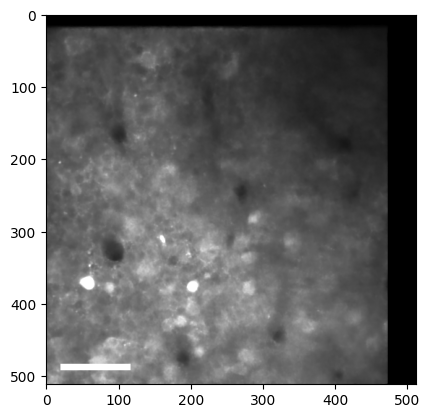

In [9]:
plt.imshow(cal[1000], cmap="gray", vmin=0, vmax=255)

In [10]:
f = TdmsFile.read("/bucket/ReiterU/OLdev/experiments/20250303_squid_cal520/sync/rec7.tdms")
g = f.groups()
twop = g[0].channels()[0][:] # line0; TTL generated by 2P scope
cam = g[0].channels()[1][:] # line1; TTL from basler camera
vis = g[0].channels()[2][:] # line2; TTL from Psychopy

# detect rising edges
twop_re = np.flatnonzero((twop[:-1] < 0.5) & (twop[1:] > 0.5))
cam_re = np.flatnonzero((cam[:-1] < 0.5) & (cam[1:] > 0.5))
vis_re = np.flatnonzero((vis[:-1] < 0.5) & (vis[1:] > 0.5))

print("Total number of frames in basler movie:", cam_re.size, cam_re.size/120)
print("Total number of frames in 2P recording:", twop_re.size, twop_re.size/15.4)

Total number of frames in basler movie: 212225 1768.5416666666667
Total number of frames in 2P recording: 26942 1749.4805194805194


In [11]:
print(twop_re[START_FRAME])
print(twop_re[END_FRAME])
print((np.abs(cam_re - twop_re[START_FRAME])).argmin())
print((np.abs(cam_re - twop_re[END_FRAME])).argmin())
print(cam_re[(np.abs(cam_re - twop_re[START_FRAME])).argmin()])
print(cam_re[(np.abs(cam_re - twop_re[END_FRAME])).argmin()])

2955296
4104089
70901
98473
2955315
4104106


In [12]:
video_path = "/bucket/ReiterU/OLdev/experiments/20250303_squid_cal520/basler/rec7_cam1.avi"
start_frame = (np.abs(cam_re - twop_re[START_FRAME])).argmin()
end_frame = (np.abs(cam_re - twop_re[END_FRAME])).argmin()
skip = 4

cap = cv2.VideoCapture(video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Total frames: {total_frames}")

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

frames = []
frame_idx = start_frame
pbar = tqdm(total=(end_frame - start_frame) // skip, desc="Loading frames", unit="frame")

while frame_idx < end_frame:
    ret, frame = cap.read()
    if not ret:
        break
    if (frame_idx - start_frame) % skip == 0:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frames.append(gray)
        pbar.update(1)
    frame_idx += 1

pbar.close()
frames = np.stack(frames)
cap.release()

Total frames: 212214


Loading frames: 100%|██████████| 6893/6893 [01:02<00:00, 110.97frame/s]


In [13]:
frames.shape

(6893, 1216, 1936)

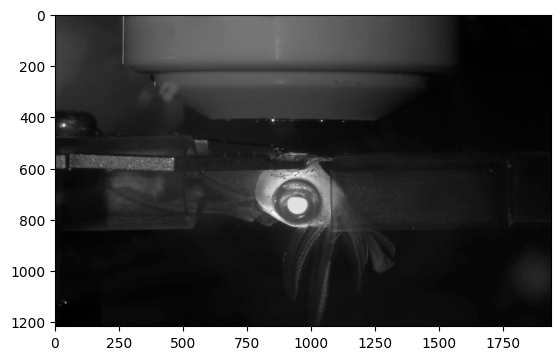

In [14]:
plt.imshow(np.clip(frames[0].astype("float") * 1.5, 0, 255), cmap="gray")

In [15]:
def export_time_aligned_concat_video(
    mov1: np.ndarray,
    mov2: np.ndarray,
    output_path: str,
    fps: int = 30,
    normalize: bool = True,
    gap_width: int = 64,
    timestamps=None,
    font_scale: float = 1.0,
    font_color: int = 255,
    font_thickness: int = 1,
    text_margin: int = 10
):
    """
    Time-aligns and horizontally concatenates two grayscale movies with optional timestamp overlay.

    Parameters:
    - mov1, mov2: np.ndarray of shape (T, H, W)
    - output_path: path to save the .mp4 video
    - fps: output video frame rate
    - normalize: if True, normalize to uint8 [0–255]
    - gap_width: vertical black gap width (default 64 px)
    - timestamps: optional list of time values (str or float) to display at top-left
    - font_scale, font_color, font_thickness: controls for timestamp text
    - text_margin: pixel margin from top-left for timestamp text
    """

    def resample_movie(movie, n_target):
        n_current = movie.shape[0]
        indices = np.linspace(0, n_current - 1, n_target).astype(int)
        return movie[indices]

    def normalize_uint8(movie):
        movie = movie.astype(np.float32)
        movie -= movie.min()
        movie /= (movie.max() + 1e-6)
        return (movie * 255).astype(np.uint8)

    def resize_with_aspect_ratio(frames, target_height):
        resized = []
        for f in frames:
            h, w = f.shape
            scale = target_height / h
            new_w = int(round(w * scale))
            resized_frame = cv2.resize(f, (new_w, target_height), interpolation=cv2.INTER_AREA)
            resized.append(resized_frame)
        return np.array(resized)

    # --- Step 1: Resample ---
    n_target = min(mov1.shape[0], mov2.shape[0])
    mov1 = resample_movie(mov1, n_target)
    mov2 = resample_movie(mov2, n_target)
    if timestamps is not None:
        timestamps = np.asarray(timestamps)
        if len(timestamps) != n_target:
            raise ValueError("Length of timestamps must match number of frames.")
        if timestamps.dtype.kind in {'f', 'i'}:
            timestamps = [f"{t:.2f} s" for t in timestamps]

    # --- Step 2: Resize with preserved aspect ratio ---
    h1, w1 = mov1.shape[1:]
    h2, w2 = mov2.shape[1:]
    target_height = min(h1, h2)

    if h1 != target_height:
        mov1 = resize_with_aspect_ratio(mov1, target_height)
    if h2 != target_height:
        mov2 = resize_with_aspect_ratio(mov2, target_height)

    # --- Step 3: Add vertical gap and concatenate ---
    gap = np.zeros((n_target, target_height, gap_width), dtype=mov1.dtype)
    concat_mov = [np.hstack((f1, gap[i], f2)) for i, (f1, f2) in enumerate(zip(mov1, mov2))]
    concat_mov = np.stack(concat_mov)

    # --- Step 4: Normalize if needed ---
    if normalize:
        concat_mov = normalize_uint8(concat_mov)
    else:
        concat_mov = concat_mov.astype(np.uint8)

    # --- Step 5: Draw timestamp and export with tqdm ---
    height, width = concat_mov.shape[1:]
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(output_path, fourcc, fps, (width, height), isColor=False)

    font = cv2.FONT_HERSHEY_PLAIN

    for i in tqdm(range(n_target), desc="Exporting video", unit="frame"):
        frame = concat_mov[i]
        if timestamps is not None:
            text = timestamps[i]
            cv2.putText(frame, text, (text_margin, text_margin + 15),
                        font, font_scale, font_color, font_thickness, lineType=cv2.LINE_AA)
        writer.write(frame)

    writer.release()
    print(f"[✓] Video saved: {output_path}")


In [16]:
timestamps = np.arange(0, cal.shape[0]) / 15.4
export_time_aligned_concat_video(cal.copy(), frames.copy(), os.path.join(tmpdir, "20250303_rec7_wave_and_behavior.mp4"), fps=60, gap_width=64, timestamps=timestamps, normalize=False)

Exporting video: 100%|██████████| 3500/3500 [00:12<00:00, 271.76frame/s]

[✓] Video saved: /flash/ReiterU/tmp/tomo_FVOZZUQZFFEH/20250303_rec7_wave_and_behavior.mp4


In [17]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1"
print(f"mkdir {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir /bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1
cp -r /flash/ReiterU/tmp/tomo_FVOZZUQZFFEH/* /bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1
